# Проект. Исследование стартапов

## Введение

Поле для вашего введения: опишите контекст и цели проекта. Чтобы изменить содержимое ячейки, дважды нажмите на неё или нажмите «Ввод».

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.


### 1.1. Вывод общей информации

In [1]:
!pip install phik -q
!pip install tzdata

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix


sns.set_theme(style="ticks")

In [3]:
readInv = pd.read_csv('data/cb_investments.csv', sep=';', low_memory=False)
display(readInv)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54289,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54290,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54291,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
54292,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
readRet = pd.read_csv('data/cb_returns.csv')
display(readRet)

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


Выведите информацию, которая необходима для принятия решений о предобработке.

In [5]:
print(readInv.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [6]:
print(readRet.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB
None


In [7]:
print(readInv.isna().sum())

name                     4857
homepage_url             8305
category_list            8817
 market                  8817
 funding_total_usd       4856
status                   6170
country_code            10129
state_code              24133
region                  10129
city                    10972
funding_rounds           4856
participants            23821
founded_at              15740
founded_month           15812
founded_quarter         15812
founded_year            15740
first_funding_at         4856
mid_funding_at          24006
last_funding_at          4856
seed                     4856
venture                  4856
equity_crowdfunding      4856
undisclosed              4856
convertible_note         4856
debt_financing           4856
angel                    4856
grant                    4856
private_equity           4856
post_ipo_equity          4856
post_ipo_debt            4856
secondary_market         4856
product_crowdfunding     4856
round_A                  4856
round_B   

In [8]:
round(readInv.isna().mean().sort_values(ascending=False),2)

state_code              0.44
mid_funding_at          0.44
participants            0.44
founded_month           0.29
founded_quarter         0.29
founded_at              0.29
founded_year            0.29
city                    0.20
country_code            0.19
region                  0.19
category_list           0.16
 market                 0.16
homepage_url            0.15
status                  0.11
name                    0.09
private_equity          0.09
round_E                 0.09
round_F                 0.09
round_D                 0.09
round_C                 0.09
round_G                 0.09
round_B                 0.09
round_A                 0.09
product_crowdfunding    0.09
secondary_market        0.09
post_ipo_debt           0.09
post_ipo_equity         0.09
venture                 0.09
grant                   0.09
angel                   0.09
debt_financing          0.09
convertible_note        0.09
undisclosed             0.09
equity_crowdfunding     0.09
seed          

### Первичное знакомство с данными

#### Файл `cd_investments.csv`

При первом просмотре данных были замечены **выбросы, присутствующие во множестве столбцов**. Также обратило на себя внимание то, что **в конце таблицы данные содержат `null`-значения** — вероятно, большинство пропусков в датасете связано именно с этими строками.

Наибольшее количество пропусков (около **44%**) сосредоточено в столбцах **`state_code`**, **`mid_funding_at`** и **`participants`**.

Можно предположить, что данные содержат **4 856 полностью пустых строк**, которые в дальнейшем потребуется обработать (например, удалить).

Также заметно, что в наименованиях столбцов присутствуют **излишние пробелы**, которые в дальнейшем будет необходимо обработать.

#### Файл `cb_returns.csv`

В данных **отсутствуют пропуски**, а наименования столбцов не требуют исправлений. При этом можно **уменьшить типы значений** (понизить размерность числовых столбцов) для оптимизации памяти.

### 1.2. Предобработка данных

Проверьте названия столбцов в датасетах: все ли они точно отражают содержимое данных и оформлены в удобном для работы стиле. При необходимости приведите их к единому аккуратному стилю.

In [9]:
#Убираем излишние пробелы в названиях столбцов

col  = list(readInv.columns)
for i in range(len(col)):
    if col[i].find(' ') == 0:
        col[i] = col[i].replace(' ','')
readInv.columns = col

Уберите в столбце `funding_total_usd` выделение разрядов и приведите его к числовому типу.

In [10]:
readInv['funding_total_usd'] = readInv['funding_total_usd'].str.replace(',','')
readInv['funding_total_usd'] = pd.to_numeric(readInv['funding_total_usd'],errors='coerce')

print(readInv.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3   market                45477 non-null  object 
 4   funding_total_usd     40907 non-null  float64
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

Обработайте типы данных в столбцах, которые хранят значения даты и времени, если это необходимо.

In [11]:
readInv['founded_at'] = readInv['founded_at'].astype('datetime64[s]')
readInv['founded_month'] = readInv['founded_month'].astype('datetime64[s]')
readInv['founded_year'] = pd.to_numeric(readInv['founded_year'])

readInv['first_funding_at'] = readInv['first_funding_at'].astype('datetime64[s]')
readInv['mid_funding_at'] = readInv['mid_funding_at'].astype('datetime64[s]')
readInv['last_funding_at'] = readInv['last_funding_at'].astype('datetime64[s]')

В датасете `cb_returns` сделайте столбец `year` индексом всего датасета, если не делали это при загрузке.

In [12]:
readRet = readRet.set_index('year')

Обработайте текстовые данные, если это необходимо. Пропуски в текстовых столбцах заполните заглушками там, где это понадобится.

In [13]:
print(f'Было удаленно {readInv.isna().all(axis=1).sum()} строк, которые являлись полностью пустыми')
readInv = readInv.dropna(how = 'all')

readInv.isna().sum()

Было удаленно 4856 строк, которые являлись полностью пустыми


name                        1
homepage_url             3449
category_list            3961
market                   3961
funding_total_usd        8531
status                   1314
country_code             5273
state_code              19277
region                   5273
city                     6116
funding_rounds              0
participants            18965
founded_at              10884
founded_month           10956
founded_quarter         10956
founded_year            10884
first_funding_at            0
mid_funding_at          19150
last_funding_at             0
seed                        0
venture                     0
equity_crowdfunding         0
undisclosed                 0
convertible_note            0
debt_financing              0
angel                       0
grant                       0
private_equity              0
post_ipo_equity             0
post_ipo_debt               0
secondary_market            0
product_crowdfunding        0
round_A                     0
round_B   

Обработайте полные дубликаты в данных и пропуски в `funding_total_usd`. избавьтесь от тех строк, которые не несут какой-либо информации либо не содержат данных о финансировании.

In [14]:
##Удаление данных в которых пропушенна информация про финансирование

print(readInv.duplicated().sum())
readInv['funding_total_usd'].dropna()

0


0        90000000.0
1         2000000.0
2         9000000.0
3         7700000.0
4          540000.0
            ...    
49433     1500000.0
49434     9000000.0
49435      250000.0
49436    34000000.0
49437       11500.0
Name: funding_total_usd, Length: 40907, dtype: float64

In [15]:
##Заполненеи пропусков среднего дня

readInv['mid_funding_at'] = readInv['mid_funding_at'].fillna(
    readInv['first_funding_at'] 
    + (readInv['last_funding_at'] - readInv['first_funding_at']) / 2
)

In [16]:
readInv['founded_month'] = readInv['founded_at'].dt.strftime('%Y-%m')

readInv['founded_quarter'] = (
    readInv['founded_at']
    .dt.to_period('Q')
    .astype(str)
    .str.replace('Q', '-Q', regex=False)
    .where(readInv['founded_at'].notna())
)


In [17]:
readInv = readInv.reset_index()
readInv.info()
readInv.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49438 entries, 0 to 49437
Data columns (total 41 columns):
 #   Column                Non-Null Count  Dtype        
---  ------                --------------  -----        
 0   index                 49438 non-null  int64        
 1   name                  49437 non-null  object       
 2   homepage_url          45989 non-null  object       
 3   category_list         45477 non-null  object       
 4   market                45477 non-null  object       
 5   funding_total_usd     40907 non-null  float64      
 6   status                48124 non-null  object       
 7   country_code          44165 non-null  object       
 8   state_code            30161 non-null  object       
 9   region                44165 non-null  object       
 10  city                  43322 non-null  object       
 11  funding_rounds        49438 non-null  float64      
 12  participants          30473 non-null  float64      
 13  founded_at            38554 non

index                       0
name                        1
homepage_url             3449
category_list            3961
market                   3961
funding_total_usd        8531
status                   1314
country_code             5273
state_code              19277
region                   5273
city                     6116
funding_rounds              0
participants            18965
founded_at              10884
founded_month           10884
founded_quarter         10884
founded_year            10884
first_funding_at            0
mid_funding_at              0
last_funding_at             0
seed                        0
venture                     0
equity_crowdfunding         0
undisclosed                 0
convertible_note            0
debt_financing              0
angel                       0
grant                       0
private_equity              0
post_ipo_equity             0
post_ipo_debt               0
secondary_market            0
product_crowdfunding        0
round_A   

### Результаты предобработки данных

В ходе преобразования данных были выполнены следующие действия:

**Файл `cd_investments.csv`:**
- Очищены названия столбцов от лишних пробелов;
- Столбцы `founded_at`, `founded_month`, `founded_year`, `first_funding_at`, `mid_funding_at`, `last_funding_at` приведены к формату даты;
- Удалены строки, в которых пропуски присутствовали во **всех** столбцах — их оказалось **4 856**;
- Удалены явные дубликаты;
- Удалены все пустые значения в столбце `funding_total_usd`;
- Восстановлены пропуски в средних значениях дат — найдено среднее значение между первой и последней датой финансирования;
- Восстановлены пропуски в столбцах `founded_month` и `founded_quarter` при помощи столбца `founded_at`.

**Файл `cd_returns.csv`:**
- Столбец `year` стал индексами.

**Обработка пропусков:** пока что было принято решение **не удалять и не заполнять оставшиеся пропуски**, так как пока не до конца понятно, какие именно данные будут использоваться в дальнейшем. Если с ними будут производиться какие-либо действия, это будет указано ниже.

**Итог по объёму данных:**
- До всех преобразований в данных было **54 293 строки**;
- После преобразований осталось **49 437 строк**, что составляет **91%** от исходного объёма данных.

---
<!-- Место для дополнений о добавлении текста позже -->

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования

Разделите все компании на три группы:

* Единичное финансирование — был всего один раунд финансирования.

* Срок финансирования до года — между первым и последним раундом финансирования прошло не более года.

* Срок финансирования более года.

Визуализируйте соотношение этих групп, создав два графика:

* По количеству компаний: Покажите, какой процент от общего числа компаний относится к каждой из трёх групп.
* По объёму инвестиций: Отобразите, какую долю от общего объёма привлечённых средств получила каждая группа.

Совет: Для ясности и согласованности используйте единую цветовую палитру для всех графиков, чтобы каждая категория (например, «Единичное финансирование») всегда отображалась одним цветом.

In [37]:
first = readInv['first_funding_at']
second = readInv['last_funding_at']

readInv['count_days'] = (second - first).dt.days

readInv.loc[readInv['count_days'] == 0, 'company_type'] = 'Единичное финансирование'
readInv.loc[((readInv['count_days'] > 0) & (readInv['count_days'] <= 365)), 'company_type'] = 'Срок финансирования до года'
readInv.loc[readInv['count_days'] > 365, 'company_type'] = 'Срок финансирования более года'

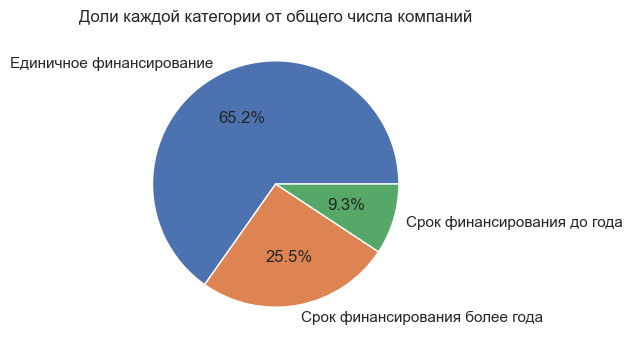

In [38]:
data = readInv['company_type'].value_counts(normalize=True)

plt.figure(figsize=(4,4))

data.plot(
    kind='pie',
    autopct='%1.1f%%',
    title='Доли каждой категории от общего числа компаний'
)

plt.ylabel('')
plt.show()

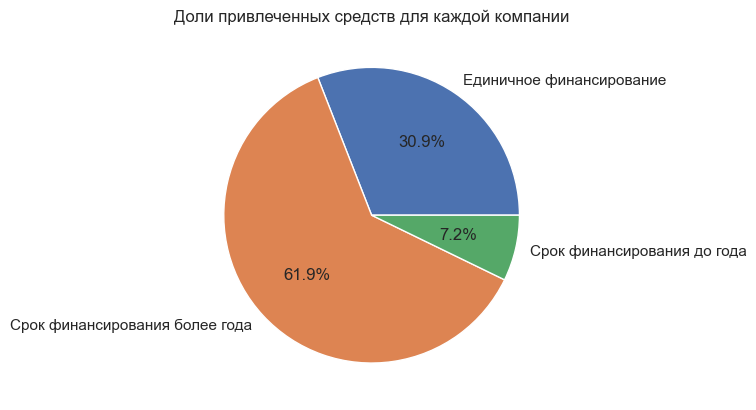

In [45]:
data = readInv.groupby('company_type')['funding_total_usd'].sum()
data = data/data.sum()*100

data.plot(
    kind='pie',
    title = 'Доли привлеченных средств для каждой компании',
    autopct='%1.1f%%',
)

plt.ylabel('')
plt.show()

### Вывод по распределению финансирования

По графикам видно, что:

- **Наибольшую долю по количеству** занимает группа **«Единичное финансирование»** — **62,5%**, а наименьшую — группа **«Срок финансирования до года»** — **9,3%**.
- **Наибольшая доля по привлечённым средствам** приходится на группу **«Срок финансирования более года»** — **61,9%**, а самая маленькая — также у группы **«Срок финансирования до года»** — **7,2%**.

### 2.2 Выделение средних и нишевых сегментов рынка

Компании указывают свой сегмент рынка в столбце `market`. Рассчитайте, как часто в датасете встречается каждый из сегментов. Сегменты, к которым относится более 120 компаний, отнесите к массовым, сегменты, в которые входит от 35 до 120 включительно, отнесите к средним, а сегменты до 35 компаний отнесите к нишевым. Рассчитайте, сколько сегментов попадает в каждую из категорий.

Постройте график распределения количества компаний в сегментах и отобразите на нём разделение на нишевые и средние сегменты.

In [ ]:
df = readInv.copy()

market_counts = df['market'].value_counts()

market_category = pd.cut(
    market_counts,
    bins=[0, 35, 121, float('inf')],
    labels=['нишевый', 'средний', 'массовый'],
    right=False
)

df['market_category'] = df['market'].map(market_category.astype(str))

df['market_category'].value_counts()

market_category
массовый    36883
средний      5640
нишевый      2954
Name: count, dtype: int64

Text(0, 0.5, 'Кол-во комапаний в категории')

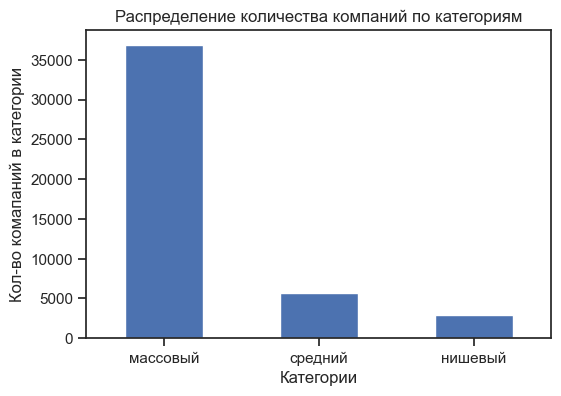

In [68]:
plt.figure(figsize=(6,4))

df['market_category'].value_counts().plot(
    kind = 'bar',
    title = 'Распределение количества компаний по категориям',
    rot =  0)

plt.xlabel('Категории')
plt.ylabel('Кол-во комапаний в категории')

In [69]:
df.loc[df['market_category'] == 'средний', 'market'] = 'mid'
df.loc[df['market_category'] == 'нишевый', 'market'] = 'niche'

In [70]:
df['market'].value_counts()

market
mid                       5640
 Software                 4781
 Biotechnology            3699
niche                     2954
 Mobile                   2151
 E-Commerce               1883
 Curated Web              1738
 Enterprise Software      1339
 Clean Technology         1230
 Health Care              1224
 Games                    1216
 Advertising              1109
 Hardware + Software      1096
 Health and Wellness       934
 Social Media              930
 Education                 894
 Finance                   890
 Manufacturing             750
 Analytics                 649
 Security                  543
 Semiconductors            509
 Consulting                493
 Hospitality               470
 Web Hosting               452
 Fashion                   402
 Real Estate               398
 News                      385
 Travel                    367
 Messaging                 307
 Music                     303
 Search                    299
 SaaS                      277
S

Оставьте в столбце `market` только массовые сегменты. Для остальных сегментов замените значения на заглушки — `niche` для нишевых и `mid` для средних.

Дальнейшие исследования выполняйте с учётом этой замены. Индивидуальные сегменты внутри средней и нишевой групп рассматривать не нужно — они объединяются в два общих сегмента.


### Вывод по распределению по сегментам рынка

По графику видно, что **наибольший объём имеет сегмент «массовый»**, а **наименьший объём — у сегмента «нишевый»**.

**Дополнительно:** столбец `market` был изменён — все наименования в категориях «средний» и «нишевый» заменены на заглушки **`mid`** и **`niche`** соответственно.

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов

Заказчика интересует обычный для рассматриваемого периода размер средств, который предоставлялся компаниям.

По предобработанному столбцу `funding_total_usd` графическим образом оцените, какой размер общего финансирования для одной компании будет типичным, а какой — выбивающимся. Укажите интервал, в котором лежат типичные значения.

Определите компании с аномальным объёмом общего финансирования — используйте метод IQR отдельно по каждому сегменту. Напомним, что все нишевые сегменты должны быть объединены в одну группу, а средние — в другую.

Определите сегменты рынка с наибольшей долей компаний, получивших аномальное финансирование, и выведите топ таких сегментов.

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии

Проверьте по датасету, можно ли считать, что вам предоставили полные данные за 2014 год. Затем исключите из датасета компании, которые вы ранее посчитали получившими аномальное финансирование.

Когда исключите аномальные записи, на основе столбцов `mid_funding_at` и `funding_rounds` оставьте в датасете данные только об определённых компаниях. Они должны были получать финансирование в годы, когда было зафиксировано 50 или более раундов финансирования.

### 3.3. Анализ типов финансирования по объёму и популярности

Постройте график, который покажет, какие типы финансирования в сумме привлекли больше всего денег. Ориентируйтесь на значения в столбцах `seed`, `venture`, `equity_crowdfunding`, `undisclosed`, `convertible_note`, `debt_financing`, `angel`, `grant`, `private_equity`, `post_ipo_equity`, `post_ipo_debt`, `secondary_market` и `product_crowdfunding`.

Также постройте график, который покажет популярность разных типов финансирования — какие типы финансирования чаще всего используются компаниями, то есть встречаются в датасете наибольшее количество раз.

Сравните графики и выделите часто используемые типы финансирования, которые при этом характеризуются небольшими объёмами, и наоборот — те, что встречаются редко, но при этом характеризуются значительным объёмом предоставленных сумм.

Постройте график суммарных объёмов возвратов от разных типов финансирования за весь период на основе дополнительного датасета.

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам

Используя столбцы `funding_total_usd` и `funding_rounds`, рассчитайте для каждой компании средний объём одного раунда финансирования.

На основе получившейся таблицы постройте графики, отражающие:
* динамику типичного размера средств, которые стартапы получали в рамках одного раунда финансирования;

* динамику общего количества раундов за каждый год, то есть насколько активно происходили инвестиции на рынке (чем больше раундов, тем выше активность).

Когда будете строить графики в этом задании и следующих, используйте данные только по тем компаниям, которые остались в датасете после предыдущих фильтраций.

На основе полученных данных ответьте на вопросы:
* В каком году типичный размер средств, собранных в рамках одного раунда, был максимальным?

* Какая тенденция наблюдалась в 2014 году по количеству раундов и средств, выделяемых в рамках каждого раунда?

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов

Составьте сводную таблицу, в которой указывается суммарный размер общего финансирования `funding_total_usd` по годам и сегментам рынка. Отберите из неё только те сегменты, которые показывали рост размера суммарного финансирования в 2014 году по сравнению с 2013.

На графике отразите, как менялся суммарный размер общего финансирования в каждом из отобранных сегментов по годам, за которые у вас достаточно данных. Рассматривайте только массовые сегменты, а средние и нишевые исключите.

На основе графика сделайте вывод о том, какие сегменты показывают наиболее быстрый и уверенный рост.

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

Заказчик хочет знать, какая часть вложенных или выданных денег со временем возвращается обратно инвесторам или финансистам. Ваша цель — для каждого года и каждого вида финансирования рассчитать нормированные значения возврата средств: то есть какую долю возвращённые средства составляют от предоставленных. При этом слишком большие аномальные значения, то есть неадекватные выбросы, нужно заменить на пропуски.

Совет: когда будете делить сумму возвращённых средств на суммарный объём привлечённого финансирования по конкретному году, добавьте к знаменателю небольшое число, например `1e-60`. Это поможет избежать деления на ноль.

Постройте график, на котором отобразите нормированные значения возврата средств для типов финансирования `venture`, `debt_financing`, `private_equity`, `seed` и `angel`.

Сделайте вывод о том, в каких типах финансирования наблюдается наиболее устойчивый рост показателя.


## Шаг 5. Итоговый вывод и рекомендации

Представьте, что на календаре 2015 год. Опираясь на результаты анализа, дайте рекомендацию заказчику:

* в какую отрасль стоит инвестировать;
* какой тип финансирования при этом будет наиболее уместным.

Подведите итоги проекта:
* опишите, какие шаги были выполнены;
* какие выводы удалось сделать;
* насколько выводы согласуются между собой или, наоборот, вызывают сомнения.

